# HMM Activity Recognition

This notebook loads only the processed, training-scaled feature tables written by `01_data_preprocessing.ipynb`. It fits a four-state Gaussian Hidden Markov Model, decodes complete recordings, and evaluates once on the eight reserved test recordings. It does not read or clean raw CSVs, extract features, tune window sizes, or fit a scaler.

Run `01_data_preprocessing.ipynb` first. Then run this notebook from the repository root or `notebooks/`.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from sklearn.metrics import confusion_matrix

ACTIVITIES=["Still","Standing","Walking","Jumping"]
HOP_SECONDS=0.5

def find_repo_root():
    for candidate in [Path.cwd(),*Path.cwd().parents]:
        if (candidate/"data"/"processed"/"window_features_scaled.csv").is_file(): return candidate
    raise FileNotFoundError("Run notebook 01 first, then open this notebook from this repository.")
REPO_ROOT=find_repo_root(); PROCESSED_DIR=REPO_ROOT/"data"/"processed"; FIGURE_DIR=REPO_ROOT/"figures"
windows=pd.read_csv(PROCESSED_DIR/"window_features_scaled.csv")
split=pd.read_csv(PROCESSED_DIR/"recording_split.csv")
scaler_parameters=pd.read_csv(PROCESSED_DIR/"scaler_parameters.csv")
FEATURES=scaler_parameters.feature.tolist()
assert len(FEATURES)==30 and all(c in windows.columns for c in FEATURES)
test_ids=set(split.query("source=='single_activity' and partition=='test'").recording_id)
train_ids=set(split.query("partition=='train'").recording_id)
assert len(test_ids)==8 and len(train_ids & test_ids)==0
assert split.query("source=='single_activity' and partition=='test'").groupby("activity").recording_id.nunique().reindex(ACTIVITIES).eq(2).all()
assert windows.loc[windows.partition=="test","recording_id"].nunique()==8
assert set(windows.loc[windows.partition=="test","recording_id"])==test_ids
print("Processed feature rows:",len(windows),"| features:",len(FEATURES))
print("Reserved test IDs:",len(test_ids),"(2 complete recordings per activity)")
print("The scaler was fit upstream on",int(scaler_parameters.training_windows.iloc[0]),"labeled training windows; no test ID was used.")

Processed feature rows: 1371 | features: 30
Reserved test IDs: 8 (2 complete recordings per activity)
The scaler was fit upstream on 1135 labeled training windows; no test ID was used.


## 1. Build training sequences

The preprocessing notebook applied the training-only scaler and wrote all transformed feature rows. This notebook selects only labeled rows assigned to the training partition for fitting. The first two mixed sequences have estimated labels and contribute uncertain transition evidence. Any omitted transition interval starts a new sequence, so no artificial transition is counted across the gap. The final test IDs are asserted absent from training.

In [4]:
train_windows=windows[(windows.partition=="train")&windows.activity.notna()].copy()
test_windows=windows[(windows.partition=="test")&(windows.source=="single_activity")].copy()
qual_windows=windows[(windows.partition=="qualitative_only")&(windows.source=="estimated_mixed_sequence")].copy()
assert set(train_windows.recording_id).isdisjoint(test_ids)
assert test_windows.recording_id.nunique()==8 and test_windows.groupby("activity").recording_id.nunique().reindex(ACTIVITIES).eq(2).all()

def make_sequences(frame):
    output=[]
    for (rid,source),group in frame.groupby(["recording_id","source"],sort=False):
        group=group.sort_values("time_center_s").reset_index(drop=True)
        breaks=np.flatnonzero(np.diff(group.time_center_s.to_numpy())>HOP_SECONDS*1.5)+1
        for part_no,idx in enumerate(np.split(np.arange(len(group)),breaks)):
            part=group.iloc[idx]
            if part.empty: continue
            X=part[FEATURES].to_numpy(float)
            y=part.activity.map({a:i for i,a in enumerate(ACTIVITIES)}).to_numpy(int)
            output.append((f"{rid}__{source}__{part_no}",X,y))
    return output

train_sequences=make_sequences(train_windows)
assert train_sequences and all(np.isfinite(X).all() for _,X,_ in train_sequences)
print("Training sequences:",len(train_sequences),"| training recordings:",train_windows.recording_id.nunique(),"| held-out IDs absent:",not (set(train_windows.recording_id)&test_ids))

Training sequences: 80 | training recordings: 74 | held-out IDs absent: True


## 2. Gaussian HMM implementation

The model has one state per activity and diagonal Gaussian emissions for continuous feature vectors. Forward-backward and Viterbi use log probabilities for numerical stability. Baum-Welch evaluates likelihood after each update, uses a combined absolute/relative tolerance, retains history, and stops at a maximum iteration count. Initial probabilities, transition rows, finite parameters, and positive variance floors are checked.

Baum-Welch updates: 5
Stopping reason: converged: |change logL|=0.000797271 <= 0.143245
Final training log likelihood: 14224.51


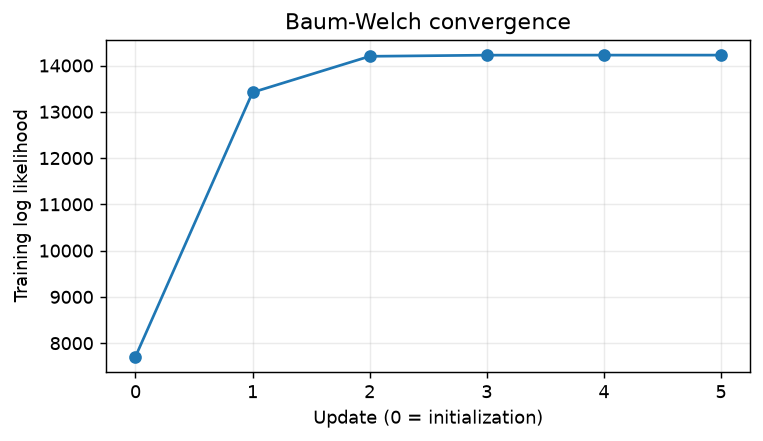

In [6]:
def _log_gaussian_diag(X, means, variances):
    d = X.shape[1]
    diff = X[:, None, :] - means[None, :, :]
    return -0.5 * (d*np.log(2*np.pi) + np.log(variances).sum(axis=1)[None, :]
                   + (diff*diff/variances[None, :, :]).sum(axis=2))

class GaussianHMM:
    def __init__(self, n_states, variance_floor=1e-3, transition_smoothing=0.5):
        self.n_states = n_states
        self.variance_floor = variance_floor
        self.transition_smoothing = transition_smoothing

    def _emission(self, X):
        return _log_gaussian_diag(X, self.means_, self.variances_)

    def _forward_backward(self, X):
        log_b = self._emission(X)
        log_a = np.log(self.A_ + 1e-300)
        log_pi = np.log(self.pi_ + 1e-300)
        T, K = log_b.shape
        alpha = np.empty((T, K)); alpha[0] = log_pi + log_b[0]
        for t in range(1, T):
            alpha[t] = log_b[t] + logsumexp(alpha[t-1][:, None] + log_a, axis=0)
        ll = logsumexp(alpha[-1])
        beta = np.zeros((T, K))
        for t in range(T-2, -1, -1):
            beta[t] = logsumexp(log_a + log_b[t+1][None, :] + beta[t+1][None, :], axis=1)
        gamma = np.exp(alpha + beta - ll)
        xis = []
        for t in range(T-1):
            lx = alpha[t][:, None] + log_a + log_b[t+1][None, :] + beta[t+1][None, :] - ll
            xis.append(np.exp(lx))
        return ll, gamma, xis

    def _validate_parameters(self):
        if not all(np.isfinite(x).all() for x in [self.pi_,self.A_,self.means_,self.variances_]): raise FloatingPointError("Non-finite HMM parameter")
        if np.any(self.pi_<0) or not np.isclose(self.pi_.sum(),1): raise ValueError("Invalid initial probabilities")
        if np.any(self.A_<0) or not np.allclose(self.A_.sum(axis=1),1): raise ValueError("Invalid transition rows")
        if np.any(self.variances_<self.variance_floor): raise ValueError("Invalid emission variances")
    def _total_ll(self,sequences):
        ll=float(sum(self._forward_backward(X)[0] for _,X,_ in sequences))
        if not np.isfinite(ll): raise FloatingPointError("Non-finite log likelihood")
        return ll
    def fit(self, sequences, max_iter=60, atol=1e-3, rtol=1e-5):
        K = self.n_states
        d = sequences[0][1].shape[1]
        # Supervised initialization from the labels attached to each training window.
        all_x = np.concatenate([x for _, x, _ in sequences])
        all_y = np.concatenate([y for _, _, y in sequences])
        self.means_ = np.vstack([all_x[all_y == k].mean(axis=0) for k in range(K)])
        self.variances_ = np.vstack([all_x[all_y == k].var(axis=0) for k in range(K)])
        self.variances_ = np.maximum(self.variances_, self.variance_floor)
        starts = np.bincount([int(y[0]) for _, _, y in sequences], minlength=K).astype(float) + 0.5
        self.pi_ = starts / starts.sum()
        counts = np.full((K, K), self.transition_smoothing, dtype=float)
        for _, _, y in sequences:
            for a, b in zip(y[:-1], y[1:]): counts[a, b] += 1
        self.A_ = counts / counts.sum(axis=1, keepdims=True)
        self._validate_parameters()
        self.log_likelihood_history_=[self._total_ll(sequences)]
        self.stopping_reason_="maximum iterations reached"
        for iteration in range(max_iter):
            pi_sum = np.zeros(K); trans_sum = np.zeros((K, K))
            gamma_sum = np.zeros(K); weighted_sum = np.zeros((K, d)); weighted_sq = np.zeros((K, d))
            for _, X, _ in sequences:
                ll, gamma, xis = self._forward_backward(X)
                pi_sum += gamma[0]
                for xi in xis: trans_sum += xi
                gamma_sum += gamma.sum(axis=0)
                weighted_sum += gamma.T @ X
                weighted_sq += gamma.T @ (X*X)
            self.pi_ = (pi_sum + 0.5) / (pi_sum.sum() + 0.5*K)
            trans_sum += self.transition_smoothing
            self.A_ = trans_sum / trans_sum.sum(axis=1, keepdims=True)
            self.means_ = weighted_sum / np.maximum(gamma_sum[:, None], 1e-12)
            self.variances_ = weighted_sq / np.maximum(gamma_sum[:, None], 1e-12) - self.means_**2
            self.variances_ = np.maximum(self.variances_, self.variance_floor)
            self._validate_parameters()
            current=self._total_ll(sequences); previous=self.log_likelihood_history_[-1]; self.log_likelihood_history_.append(current)
            threshold=atol+rtol*abs(previous)
            if abs(current-previous)<=threshold:
                self.stopping_reason_=f"converged: |change logL|={abs(current-previous):.6g} <= {threshold:.6g}"
                break
        return self

    def predict(self, X):
        log_b = self._emission(X)
        log_a = np.log(self.A_ + 1e-300); log_pi = np.log(self.pi_ + 1e-300)
        T, K = log_b.shape
        score = np.empty((T, K)); back = np.zeros((T, K), dtype=int)
        score[0] = log_pi + log_b[0]
        for t in range(1, T):
            candidates = score[t-1][:, None] + log_a
            back[t] = candidates.argmax(axis=0)
            score[t] = candidates.max(axis=0) + log_b[t]
        path = np.empty(T, dtype=int); path[-1] = score[-1].argmax()
        for t in range(T-2, -1, -1): path[t] = back[t+1, path[t+1]]
        return path

    def emission_log_prob(self, X):
        return self._emission(X)


model=GaussianHMM(len(ACTIVITIES)).fit(train_sequences)
print("Baum-Welch updates:",len(model.log_likelihood_history_)-1)
print("Stopping reason:",model.stopping_reason_)
print("Final training log likelihood:",round(model.log_likelihood_history_[-1],2))
fig,ax=plt.subplots(figsize=(6,3.5)); ax.plot(range(len(model.log_likelihood_history_)),model.log_likelihood_history_,marker="o")
ax.set(xlabel="Update (0 = initialization)",ylabel="Training log likelihood",title="Baum-Welch convergence"); ax.grid(alpha=.25); fig.tight_layout(); fig.savefig(FIGURE_DIR/"convergence.png",dpi=180); plt.show()

## 3. Final held-out evaluation

A recording receives one prediction: the most frequent Viterbi state across its windows. The final set is exactly two complete recordings per activity. These results are reported at recording level, not as hundreds of correlated overlapping-window predictions. No grouped cross-validation or tuning is run in this notebook; the final eight recordings remain a one-time held-out evaluation.

Recording-level accuracy: 1.000 (8/8)


,recording_id,actual,predicted,windows
0,Still_19_2026-10-28_09-14-03,Still,Still,15
1,Still_20_2026-10-28_09-14-13,Still,Still,14
2,Standing_19_2026-10-29_12-52-25,Standing,Standing,14
3,Standing_20_2026-10-29_12-52-36,Standing,Standing,13
4,Walking_19_2026-10-29_19-24-41,Walking,Walking,15
5,Walking_20_2026-10-29_19-24-51,Walking,Walking,16
6,Jumping_19_2026-10-29_17-48-52,Jumping,Jumping,17
7,Jumping_20_2026-10-29_17-49-06,Jumping,Jumping,15


,Still,Standing,Walking,Jumping
Actual,,,,
Still,2,0,0,0
Standing,0,2,0,0
Walking,0,0,2,0
Jumping,0,0,0,2


,activity,test_recordings,sensitivity,specificity,accuracy
0,Still,2,1.0,1.0,1.0
1,Standing,2,1.0,1.0,1.0
2,Walking,2,1.0,1.0,1.0
3,Jumping,2,1.0,1.0,1.0


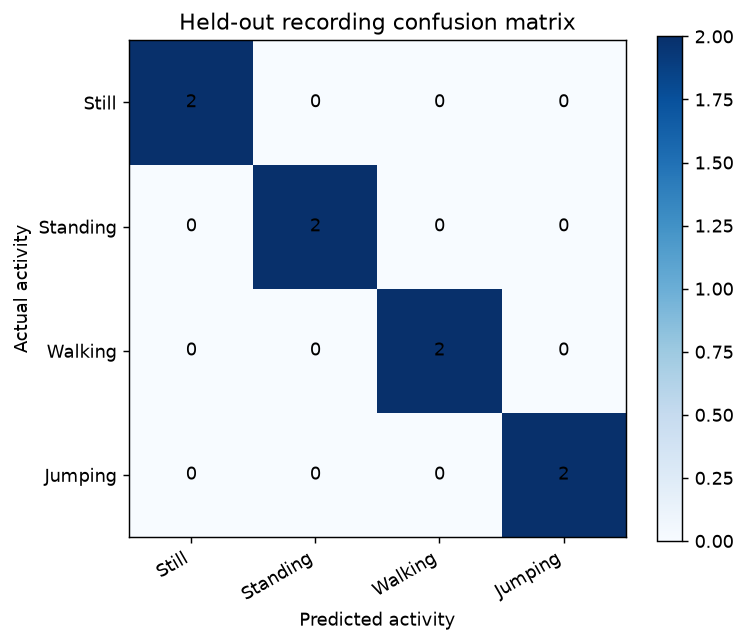

In [8]:
y_true=[]; y_pred=[]; prediction_rows=[]
for rid,group in test_windows.groupby("recording_id",sort=False):
    group=group.sort_values("time_center_s"); X=group[FEATURES].to_numpy(float)
    states=model.predict(X); pred=int(np.bincount(states,minlength=len(ACTIVITIES)).argmax())
    actual=ACTIVITIES.index(group.activity.iloc[0]); y_true.append(actual); y_pred.append(pred)
    prediction_rows.append({"recording_id":rid,"actual":ACTIVITIES[actual],"predicted":ACTIVITIES[pred],"windows":len(X)})
predictions=pd.DataFrame(prediction_rows); display(predictions)
cm=confusion_matrix(y_true,y_pred,labels=range(len(ACTIVITIES)))
display(pd.DataFrame(cm,index=ACTIVITIES,columns=ACTIVITIES).rename_axis("Actual"))
accuracy=np.trace(cm)/cm.sum(); metric_rows=[]
for i,activity in enumerate(ACTIVITIES):
    tp=cm[i,i]; fn=cm[i,:].sum()-tp; fp=cm[:,i].sum()-tp; tn=cm.sum()-tp-fn-fp
    metric_rows.append({"activity":activity,"test_recordings":int(cm[i].sum()),"sensitivity":tp/(tp+fn) if tp+fn else np.nan,"specificity":tn/(tn+fp) if tn+fp else np.nan,"accuracy":accuracy})
metrics=pd.DataFrame(metric_rows); display(metrics.round(3)); print(f"Recording-level accuracy: {accuracy:.3f} ({int(np.trace(cm))}/{int(cm.sum())})")
fig,ax=plt.subplots(figsize=(6,5)); im=ax.imshow(cm,cmap="Blues")
ax.set(xticks=range(4),yticks=range(4),xticklabels=ACTIVITIES,yticklabels=ACTIVITIES,xlabel="Predicted activity",ylabel="Actual activity",title="Held-out recording confusion matrix")
plt.setp(ax.get_xticklabels(),rotation=30,ha="right")
for i in range(4):
    for j in range(4): ax.text(j,i,cm[i,j],ha="center",va="center")
fig.colorbar(im,ax=ax); fig.tight_layout(); fig.savefig(FIGURE_DIR/"confusion_matrix.png",dpi=180); plt.show()

## 4. Transition, emission, and qualitative sequence views

The transition matrix shows discrete state-to-state probabilities. The emissions are continuous diagonal Gaussian distributions, so the heatmap shows row-standardized mean Gaussian emission log density for held-out windows, not a discrete symbol-probability table. Mixed-sequence activity labels are estimates only; their decoded path is a qualitative illustration, not a ground-truth score.

Limitation: recordings are from one participant and one iPhone XR; cross-person/device generalization is untested.


,Still,Standing,Walking,Jumping
Current state,,,,
Still,0.994382,0.001873,0.001873,0.001873
Standing,0.002326,0.979025,0.016319,0.002330
Walking,0.001552,0.029520,0.930127,0.038801
Jumping,0.001931,0.005794,0.017383,0.974891


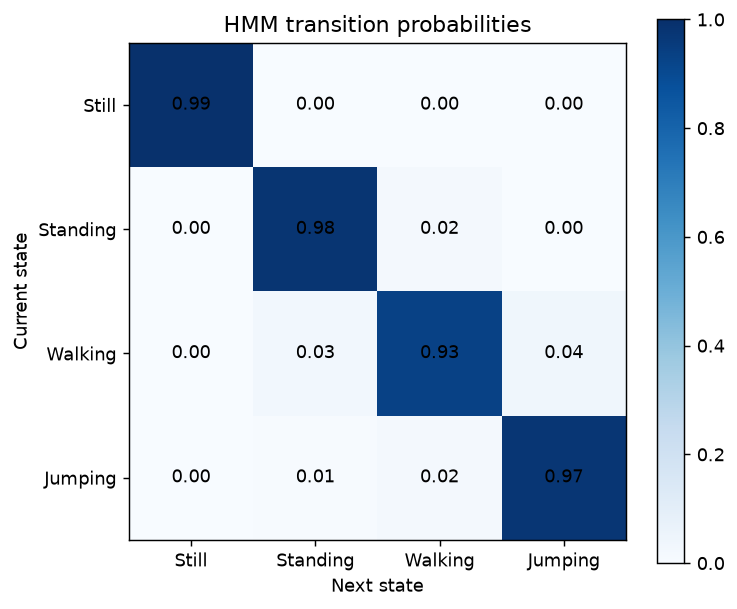

,Still,Standing,Walking,Jumping
Actual class,,,,
Still,62.745074,-62.647065,-435.189562,-297.301071
Standing,-70.788982,40.274225,-55.161269,-111.187856
Walking,-15716.537649,-2866.782241,-7.851708,-78.287144
Jumping,-123688.580016,-66360.593263,-13899.593376,-59.192543


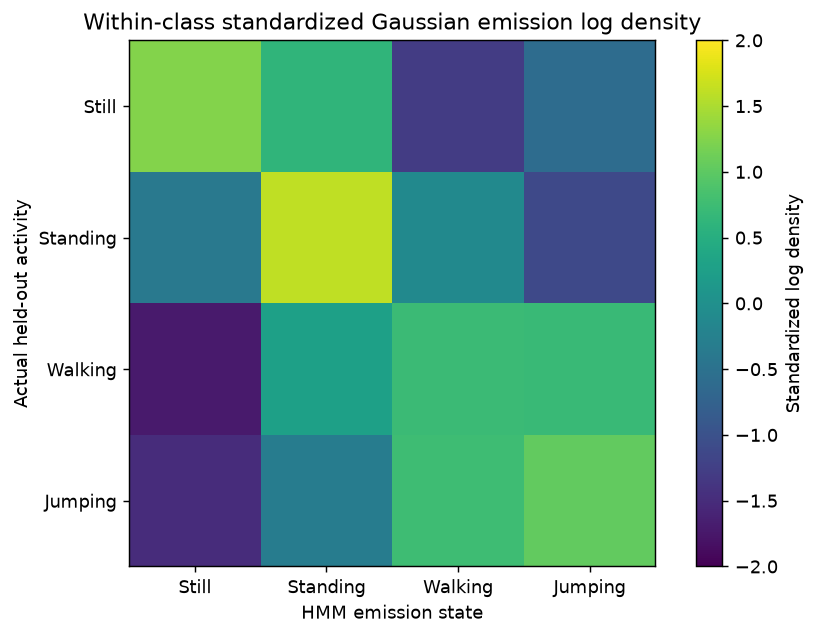

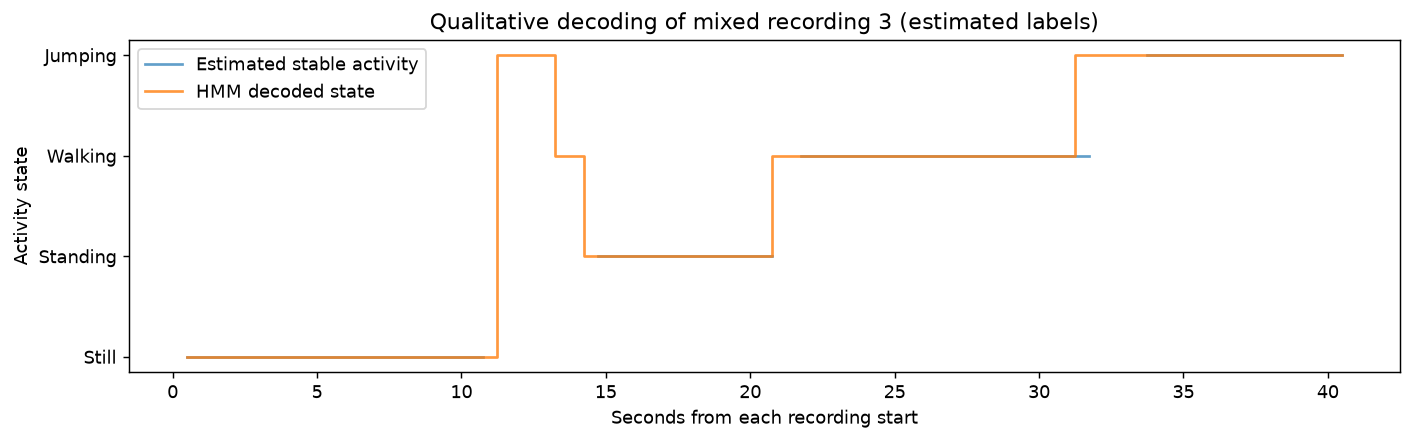

In [10]:
display(pd.DataFrame(model.A_,index=ACTIVITIES,columns=ACTIVITIES).rename_axis("Current state"))
fig,ax=plt.subplots(figsize=(6,5)); im=ax.imshow(model.A_,cmap="Blues",vmin=0,vmax=1)
ax.set(xticks=range(4),yticks=range(4),xticklabels=ACTIVITIES,yticklabels=ACTIVITIES,xlabel="Next state",ylabel="Current state",title="HMM transition probabilities")
for i in range(4):
    for j in range(4): ax.text(j,i,f"{model.A_[i,j]:.2f}",ha="center",va="center")
fig.colorbar(im,ax=ax); fig.tight_layout(); fig.savefig(FIGURE_DIR/"transition_probabilities.png",dpi=180); plt.show()
emission_scores=np.zeros((4,4))
for actual in range(4):
    X=test_windows.loc[test_windows.activity==ACTIVITIES[actual],FEATURES].to_numpy(float)
    emission_scores[actual]=model.emission_log_prob(X).mean(axis=0)
display(pd.DataFrame(emission_scores,index=ACTIVITIES,columns=ACTIVITIES).rename_axis("Actual class"))
emission_display=(emission_scores-emission_scores.mean(axis=1,keepdims=True))/emission_scores.std(axis=1,keepdims=True)
fig,ax=plt.subplots(figsize=(7,5)); im=ax.imshow(emission_display,cmap="viridis",vmin=-2,vmax=2)
ax.set(xticks=range(4),yticks=range(4),xticklabels=ACTIVITIES,yticklabels=ACTIVITIES,xlabel="HMM emission state",ylabel="Actual held-out activity",title="Within-class standardized Gaussian emission log density")
fig.colorbar(im,ax=ax,label="Standardized log density"); fig.tight_layout(); fig.savefig(FIGURE_DIR/"emission_log_densities.png",dpi=180); plt.show()
# Decode each stable segment of mixed recording 3 independently across unlabeled gaps.
seq=qual_windows.sort_values("time_center_s").copy(); breaks=np.flatnonzero(np.diff(seq.time_center_s.to_numpy())>HOP_SECONDS*1.5)+1
seq["predicted_state"]=np.nan
for idx in np.split(np.arange(len(seq)),breaks):
    if len(idx): seq.loc[seq.index[idx],"predicted_state"]=model.predict(seq.iloc[idx][FEATURES].to_numpy(float))
fig,ax=plt.subplots(figsize=(11,3.5)); times=seq.time_center_s.to_numpy()
ref=seq.activity.map({a:i for i,a in enumerate(ACTIVITIES)}).to_numpy(float)
ax.step(times,ref,where="mid",label="Estimated stable activity",alpha=.7); ax.step(times,seq.predicted_state,where="mid",label="HMM decoded state",alpha=.8)
ax.set(yticks=range(4),yticklabels=ACTIVITIES,xlabel="Seconds from each recording start",ylabel="Activity state",title="Qualitative decoding of mixed recording 3 (estimated labels)")
ax.legend(); fig.tight_layout(); plt.show()
print("Limitation: recordings are from one participant and one iPhone XR; cross-person/device generalization is untested.")

## 5. Interpretation and limitations

The evaluation describes performance on eight unseen recordings from the same participant and iPhone XR. Perfect accuracy on this small set does not establish broader generalization. The three mixed sequences have estimated activity boundaries and are not scored as ground truth. More participants, phone placements, sessions, and exact transition markers are needed to test robustness. The current model uses diagonal Gaussian emissions, so it does not model correlations between features.